# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_:
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M.
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

![Convergence Plot of the Four Root-Finding Methods](overlay.png) <img src="../Claire/Exercise 7_updated/overlay.jpg" width=45%>
***Figure 5** shows the plot of the convergence of the values towards the root of $f(x)$. This overlays the convergence curves, plotting $x_i$ vs. $i$ for each of the four methods, with $x_i$ as the output of the method on the $i$th step.*


### Report discussion

**a)** Figure 5 overlays the convergence of all four root-finding methods, plotting each iterate $x_i$ against the step number $i$. Every curve settles onto one of the three roots of $f(x)$, at $x$ ≈ −1.19, 2 and 4.60 (dashed lines), so all methods converge. Newton’s and secant methods reach the simple roots fastest, taking only around 6 to 40 steps, while bisection steadily halves its bracket and needs about 27 steps, and fixed-point takes about 27 to 32 steps because its error shrinks only by a constant factor per step. The curves ending at $x$ = 2 take longest, since it is a double root where $df$ = 0, so convergence is only linear. The secant run from (−2, 0) lands on $x$ = 2 instead of −1.19, showing that the starting guesses decide which root is found.

**b)** Fixed-point is simple and needs no derivative, but it converges slowly and is only accurate if |1 + a·f′| < 1, so the relaxation factor $a$ must be tuned for each root. Bisection is guaranteed to converge once a sign change is bracketed, but it is slow and cannot find roots where f does not change sign, like $x$ = 2. Newton’s method converges quadratically near simple roots and needs only one guess, but it requires the derivative, can diverge or jump to a different root from poor guesses, and slows to linear convergence at the double root. Secant avoids the derivative and is nearly as fast as Newton, but it needs two guesses and, like Newton, is not guaranteed to converge or to find the nearest root.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=-5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

### **I.** Implementing the root finders manually to find the roots of the given function.

In [2]:
# Setting up the function and its derivative
def f(x):
    return (-x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8)

def df(x):
    return (-5*x**4 + 16*x**3 - 12*x**2 + (x**2 + 2*x)*np.exp(x) - 4*x - 4*(x + 1)*np.exp(x) + 8 + 4*np.exp(x))

In [3]:
# Defining tolerance and maximum iterations
tol = 1.e-8
kmax = 200

#### Using **fixed-point method** with a relaxation factor $a$ and an initial guess $x_0$:

root = -1.19268577, steps = 32


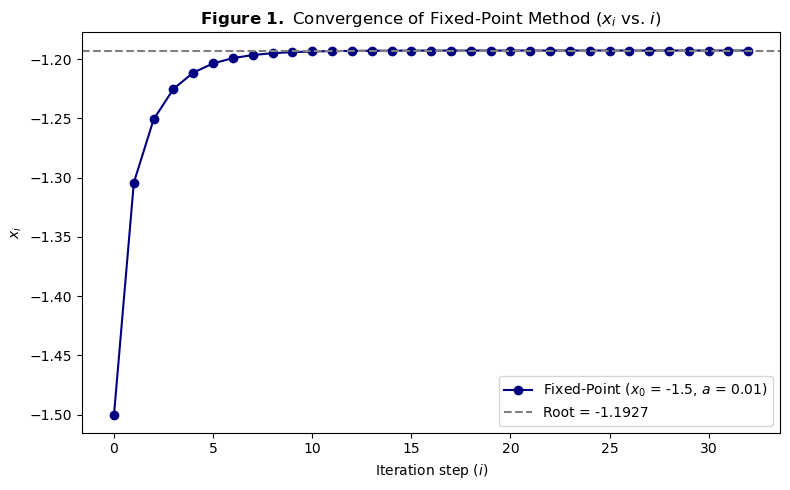

In [4]:
def fixed_point(f, x0, a=1):
    xs = [x0]
    x = x0
    for k in range(1, kmax):
        xnew = x + a*f(x)
        xs.append(xnew)
        if abs(xnew - x) < tol:
            break
        x = xnew
    else:
        print("fixedpoint: maxed out")
    return np.array(xs)

# Setting initial conditions
x0 = -1.5
a = 0.01
xs = fixed_point(f, x0, a)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting the convergence of the values towards the root
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Fixed-Point ($x_0$ = {x0}, $a$ = {a})')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r'$\bf{Figure\ 1.}$ Convergence of Fixed-Point Method ($x_i$ vs. $i$)')

ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()

#### Using **bisection method** with bracketing and two bounds

root = -1.19268576, steps = 27


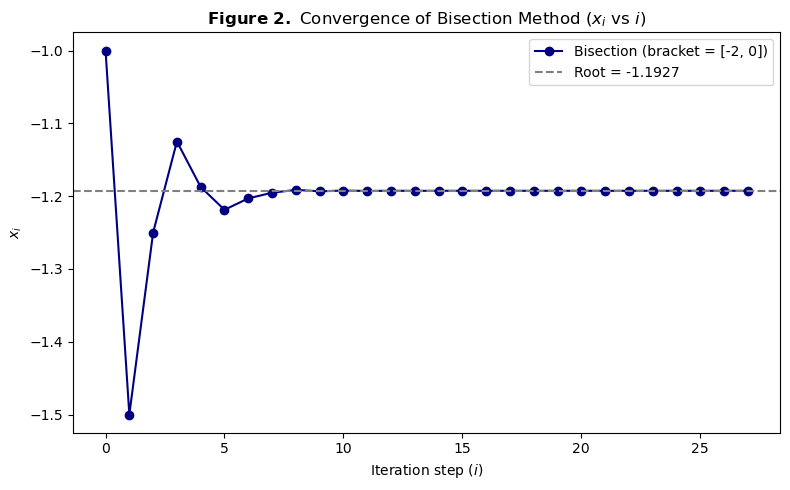

In [5]:
# Manual Implementation
def bisection(f, x0, x1): # x0 and x1 are the two ends of the bracket
    if f(x0)*f(x1) > 0:
       raise ValueError("bisection: no sign change in bracket")
    xs = []
    for k in range(1, kmax):
        xs_k = 0.5*(x0 + x1)
        xs.append(xs_k)
        if f(x0)*f(xs_k) < 0:
            x1 = xs_k
        else:
            x0 = xs_k
        if abs(x1 - x0) < tol:
            break
    else:
        print("bisection: maxed out")
    return np.array(xs)

# Setting initial conditions
x0 = -2
x1 = 0
xs = bisection(f, x0, x1)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting Bisection Method
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Bisection (bracket = [{x0}, {x1}])')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r'$\bf{Figure\ 2.}$ Convergence of Bisection Method ($x_i$ vs $i$)')

ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()

#### Using **Newton's method**, along with the function's derivative $df$ and an initial guess $x_0$:

root = -1.19268577, steps = 7


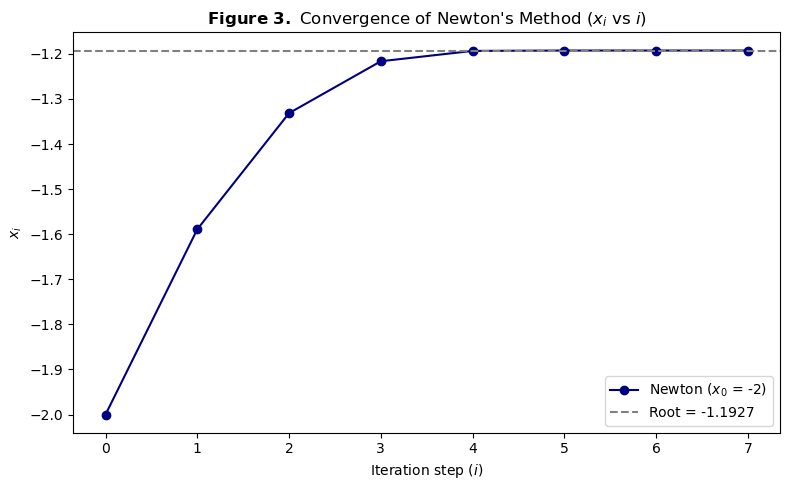

In [6]:
# Manual Implementation
def newton(f, df, x0):
    xs = [x0]
    x = x0
    for k in range(1, kmax):
        xnew = x - f(x)/df(x)
        xs.append(xnew)
        if abs(xnew -x) < tol:
            break
        x = xnew
    else:
        print("newton: maxed out")
    return np.array(xs)

# Setting initial conditions
x0 = -2
xs = newton(f, df, x0)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting Newton's Method
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Newton ($x_0$ = {x0})')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r"$\bf{Figure\ 3.}$ Convergence of Newton's Method ($x_i$ vs $i$)")
ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()

#### Using **secant method**, with two initial guesses $x_0$ and $x_1$:

root = -1.19268577, steps = 9


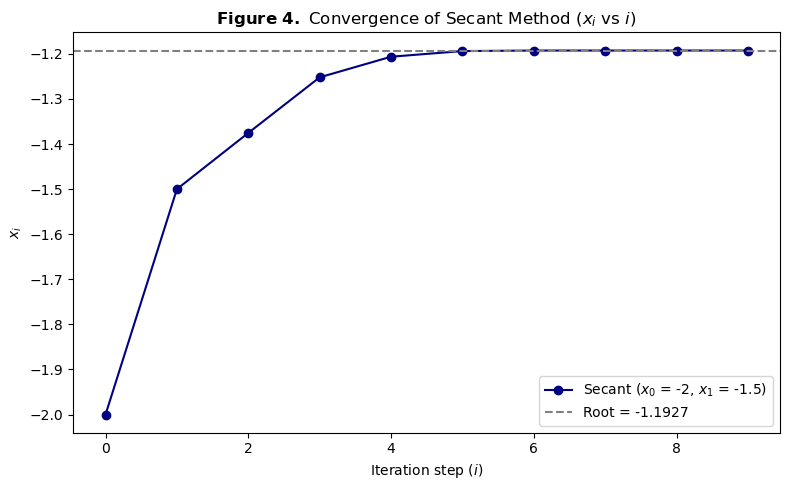

In [7]:
# Manual Implementation
def secant(f, x0, x1):
    xs = [x0, x1]
    for k in range(1, kmax):
        xnew = x1 - f(x1)*(x1-x0) / (f(x1) - f(x0))
        xs.append(xnew)
        if abs(xnew -x1) < tol:
            break
        x0, x1 = x1, xnew
    else:
        print("secant: maxed out")
    return np.array(xs)

# Setting initial conditions
x0 = -2
x1 = -1.5
xs = secant(f, x0, x1)
root = xs[-1]
print(f"root = {root:.8f}, steps = {len(xs)-1}")

# Plotting Secant Method
iterations = np.arange(len(xs))

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(iterations, xs, 'o-', color='navy',
        label=f'Secant ($x_0$ = {x0}, $x_1$ = {x1})')
ax.axhline(root, color='gray', linestyle='--', label=f'Root = {root:.4f}')

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r'$\bf{Figure\ 4.}$ Convergence of Secant Method ($x_i$ vs $i$)')

ax.grid(False)
ax.legend()

plt.tight_layout()
plt.show()

### **II.** Plotting the function from $x=-2$ to $x=5$ and overlaying the convergence curves on a single plot.

Fixed-point, x0=-1.5, a=0.01             root = -1.19268577, steps = 32
Fixed-point, x0=4.4, a=-0.002            root = 4.59586356, steps = 27
Bisection, [-2, 0]                       root = -1.19268576, steps = 27
Bisection, [3, 5]                        root = 4.59586356, steps = 27
Newton, x0=-2                            root = -1.19268577, steps = 7
Newton, x0=1.5 (double root)             root = 2.00000002, steps = 41
Newton, x0=5                             root = 4.59586356, steps = 6
Secant, x0=-2, x1=-1.5                   root = -1.19268577, steps = 9
Secant, x0=4, x1=5                       root = 4.59586356, steps = 12
Secant, x0=-2, x1=0 (double root)        root = 2.00000007, steps = 40


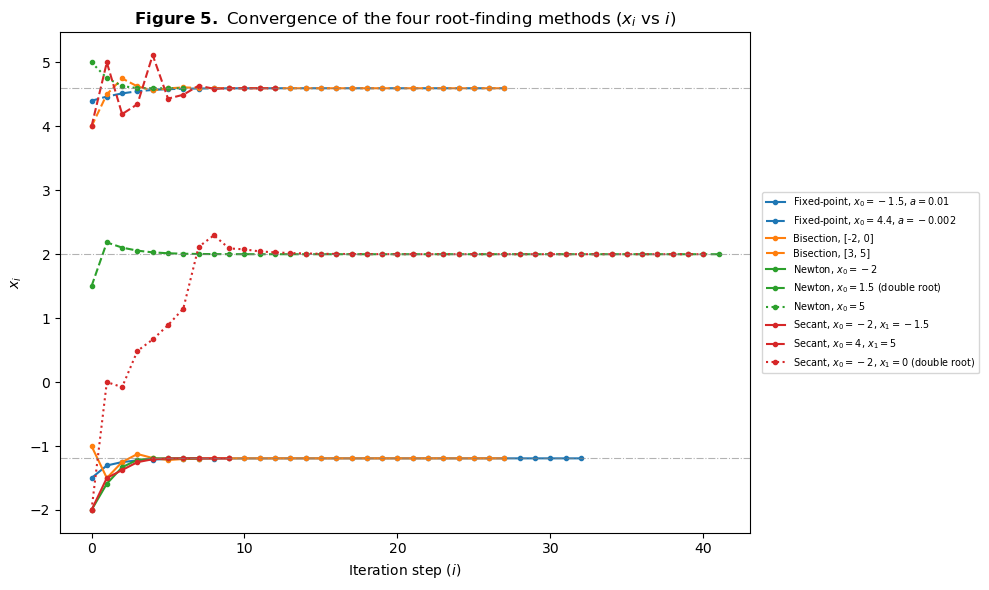

In [8]:
runs = [
    ('Fixed-point, $x_0=-1.5$, $a=0.01$', fixed_point(f, -1.5, a=0.01), 'tab:blue', '-'),
    ('Fixed-point, $x_0=4.4$, $a=-0.002$', fixed_point(f, 4.4, a=-0.002), 'tab:blue', '--'),
    ('Bisection, [-2, 0]', bisection(f, -2., 0.), 'tab:orange', '-'),
    ('Bisection, [3, 5]', bisection(f, 3., 5.), 'tab:orange', '--'),
    ('Newton, $x_0=-2$', newton(f, df, -2), 'tab:green', '-'),
    ('Newton, $x_0=1.5$ (double root)', newton(f, df, 1.5), 'tab:green', '--'),
    ('Newton, $x_0=5$', newton(f, df, 5.), 'tab:green', ':'),
    ('Secant, $x_0=-2$, $x_1=-1.5$', secant(f, -2., -1.5), 'tab:red', '-'),
    ('Secant, $x_0=4$, $x_1=5$', secant(f, 4., 5.), 'tab:red', '--'),
    ('Secant, $x_0=-2$, $x_1=0$ (double root)', secant(f, -2., 0.), 'tab:red', ':'),
]

for label, xs, c, ls in runs:
    clean = label.replace('$', '').replace('_', '')
    print(f"{clean:40s} root = {xs[-1]:.8f}, steps = {len(xs)-1}")

# Overlay plot
fig, ax = plt.subplots(figsize=(10, 6))

x = np.linspace(-2, 5, 1000)

for label, xs, c, ls in runs:
    ax.plot(np.arange(len(xs)), xs, ls, color=c, marker='o', ms=3, label=label)

# reference lines at the three roots
for r in [-1.19268577, 2.0, 4.59586356]:
    ax.axhline(r, color='gray', lw=0.8, ls='-.', alpha=0.6)

ax.set_xlabel('Iteration step ($i$)')
ax.set_ylabel('$x_i$')
ax.set_title(r'$\bf{Figure\ 5.}$ Convergence of the four root-finding methods ($x_i$ vs $i$)')
ax.grid(False)
ax.legend(fontsize=7, loc='center left', bbox_to_anchor=(1.01, 0.5))

plt.tight_layout()
plt.savefig('overlay.png', dpi=150)
plt.show()

#### **Problem 1 code summary**

This script finds the roots of $f(x)$ with fixed-point (relaxation), bisection, Newton’s and secant methods, each implemented by hand as a loop that updates its estimate until successive values differ by less than tol (or kmax is reached). I made each function return the whole array of iterates instead of only the final root, because the report figure plots $xᵢ$ vs. $i$, and I collected every run in one runs list of (label, iterates, color, linestyle) so a single loop overlays all the curves and a new starting guess takes only one extra line. I used several guesses per method because f has three roots, including a double root at $x = 2$ where bisection finds no sign change and Newton and secant converge only linearly, and I tuned the sign and size of a in the relaxation method (positive near −1.19, negative near 4.6) so that $|1 + a·f′(x^*)| < 1$ and the iteration converges.